# Data Analysis and Visualization - Lab 2
**Dataset:** Penguins
**Tasks:** 9 visualization and outlier detection tasks

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

## 1. Load and Clean the Penguin Dataset

In [2]:
df = sns.load_dataset('penguins')
print(f"Original shape: {df.shape}")
print(f"\nMissing values:\n{df.isnull().sum()}")
print(f"\nData types:\n{df.dtypes}")

Original shape: (344, 7)

Missing values:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Data types:
species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
dtype: object


In [3]:
# Clean the data
df_clean = df.copy()

# Fill numeric missing values with median (robust to outliers)
numeric_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Fill categorical missing values with mode
df_clean['sex'] = df_clean['sex'].fillna(df_clean['sex'].mode()[0])

print(f"Cleaned shape: {df_clean.shape}")
print(f"\nMissing values after cleaning:\n{df_clean.isnull().sum()}")
print(f"\nFirst 5 rows:\n{df_clean.head()}")

Cleaned shape: (344, 7)

Missing values after cleaning:
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

First 5 rows:
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen           39.10           18.7              181.0   
1  Adelie  Torgersen           39.50           17.4              186.0   
2  Adelie  Torgersen           40.30           18.0              195.0   
3  Adelie  Torgersen           44.45           17.3              197.0   
4  Adelie  Torgersen           36.70           19.3              193.0   

   body_mass_g     sex  
0       3750.0    Male  
1       3800.0  Female  
2       3250.0  Female  
3       4050.0    Male  
4       3450.0  Female  


In [4]:
# Save cleaned dataset
df_clean.to_csv('penguins_cleaned.csv', index=False)
print("Cleaned dataset saved as 'penguins_cleaned.csv'")

Cleaned dataset saved as 'penguins_cleaned.csv'


## Task 1: Bar Chart - Compare a Category
**Average body mass by species**

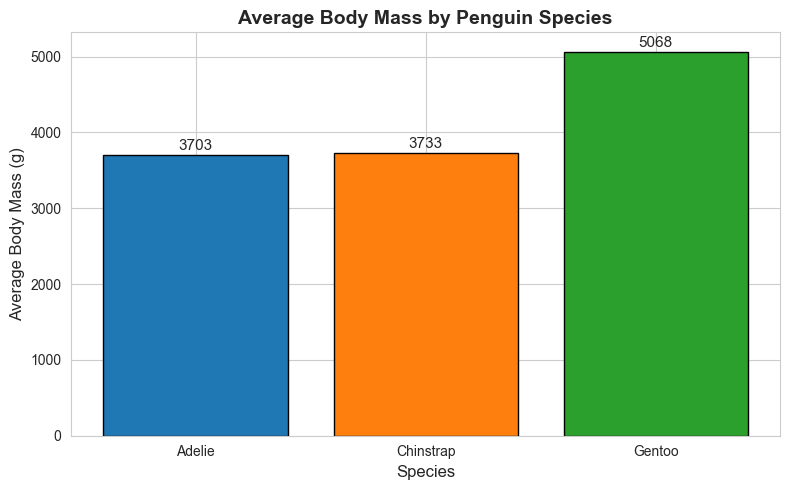

In [5]:
avg_mass_by_species = df_clean.groupby('species')['body_mass_g'].mean().reset_index()

plt.figure(figsize=(8, 5))
bars = plt.bar(avg_mass_by_species['species'], avg_mass_by_species['body_mass_g'], 
               color=['#1f77b4', '#ff7f0e', '#2ca02c'], edgecolor='black')
plt.title('Average Body Mass by Penguin Species', fontsize=14, fontweight='bold')
plt.xlabel('Species', fontsize=12)
plt.ylabel('Average Body Mass (g)', fontsize=12)

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 20,
             f'{height:.0f}', ha='center', va='bottom', fontsize=11)

plt.tight_layout()
plt.show()

## Task 2: Count Plot - Category Frequency
**Count of penguins by species**

/var/folders/lj/fk6tn4cj2454_156kjkr_l9h0000gn/T/ipykernel_56037/4150925919.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df_clean, x='species', palette=['#1f77b4', '#ff7f0e', '#2ca02c'])


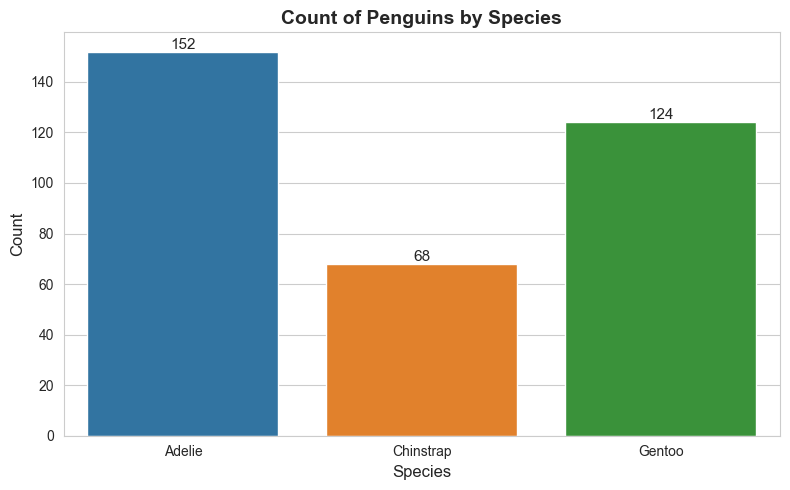

Species counts:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

Most common species: Adelie (152 penguins)


In [6]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df_clean, x='species', palette=['#1f77b4', '#ff7f0e', '#2ca02c'])
plt.title('Count of Penguins by Species', fontsize=14, fontweight='bold')
plt.xlabel('Species', fontsize=12)
plt.ylabel('Count', fontsize=12)

# Add count labels on bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha = 'center', va = 'bottom', fontsize=11)

plt.tight_layout()
plt.show()

species_counts = df_clean['species'].value_counts()
print(f"Species counts:\n{species_counts}")
print(f"\nMost common species: {species_counts.index[0]} ({species_counts.iloc[0]} penguins)")

## Task 3: Histogram - Distribution Shape
**Distribution of body mass**

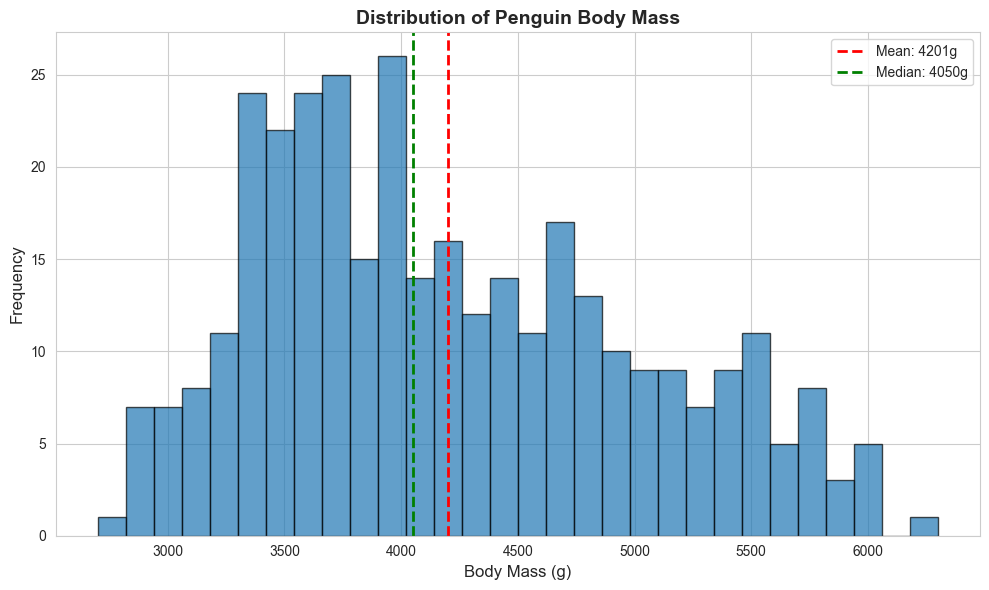

Skewness: 0.473
The distribution is approximately symmetric.


In [7]:
plt.figure(figsize=(10, 6))
plt.hist(df_clean['body_mass_g'], bins=30, edgecolor='black', alpha=0.7, color='#1f77b4')
plt.title('Distribution of Penguin Body Mass', fontsize=14, fontweight='bold')
plt.xlabel('Body Mass (g)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.axvline(df_clean['body_mass_g'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df_clean["body_mass_g"].mean():.0f}g')
plt.axvline(df_clean['body_mass_g'].median(), color='green', linestyle='--', linewidth=2, label=f'Median: {df_clean["body_mass_g"].median():.0f}g')
plt.legend()
plt.tight_layout()
plt.show()

# Describe shape
from scipy.stats import skew
skewness = skew(df_clean['body_mass_g'])
print(f"Skewness: {skewness:.3f}")
if skewness > 0.5:
    shape = "skewed right (positive skew)"
elif skewness < -0.5:
    shape = "skewed left (negative skew)"
else:
    shape = "approximately symmetric"
print(f"The distribution is {shape}.")

## Task 4: Box Plot - Visual Outlier Detection
**Box plot of body mass by species**

/var/folders/lj/fk6tn4cj2454_156kjkr_l9h0000gn/T/ipykernel_56037/498372243.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(data=df_clean, x='species', y='body_mass_g', palette=['#1f77b4', '#ff7f0e', '#2ca02c'])


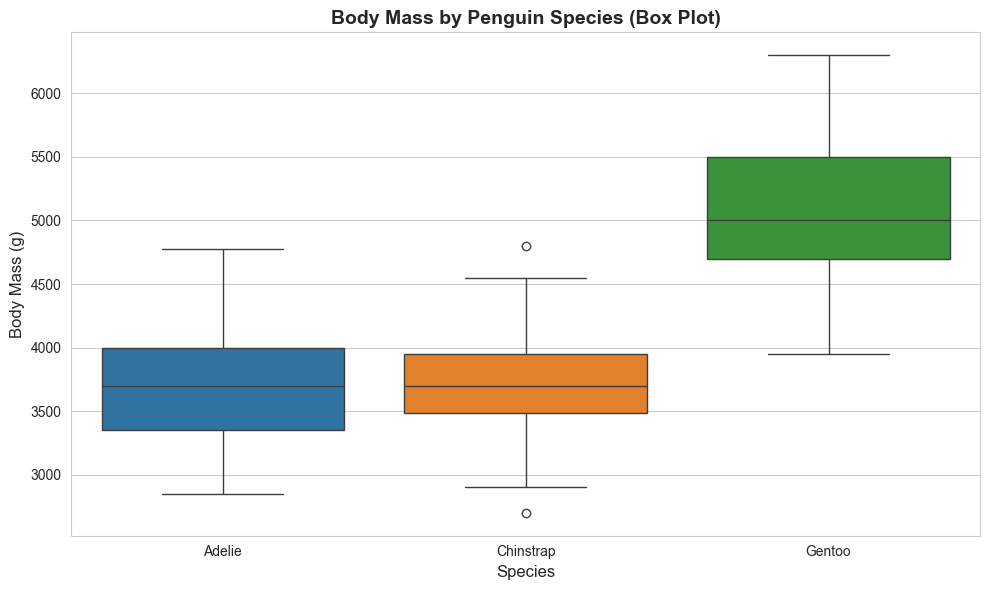

Adelie: 0 outliers (bounds: 2375 - 4975)
Chinstrap: 2 outliers (bounds: 2794 - 4644)
Gentoo: 0 outliers (bounds: 3500 - 6700)


In [8]:
plt.figure(figsize=(10, 6))
ax = sns.boxplot(data=df_clean, x='species', y='body_mass_g', palette=['#1f77b4', '#ff7f0e', '#2ca02c'])
plt.title('Body Mass by Penguin Species (Box Plot)', fontsize=14, fontweight='bold')
plt.xlabel('Species', fontsize=12)
plt.ylabel('Body Mass (g)', fontsize=12)
plt.tight_layout()
plt.show()

# Count visual outliers per species
for species in df_clean['species'].unique():
    species_data = df_clean[df_clean['species'] == species]['body_mass_g']
    Q1 = species_data.quantile(0.25)
    Q3 = species_data.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = species_data[(species_data < lower) | (species_data > upper)]
    print(f"{species}: {len(outliers)} outliers (bounds: {lower:.0f} - {upper:.0f})")

## Task 5: Outlier Detection - IQR Method
**Using body_mass_g column (all species combined)**

In [9]:
col = 'body_mass_g'
Q1 = df_clean[col].quantile(0.25)
Q3 = df_clean[col].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outliers_iqr = df_clean[(df_clean[col] < lower) | (df_clean[col] > upper)]

print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Lower bound: {lower:.2f}")
print(f"Upper bound: {upper:.2f}")
print(f"Number of outliers (IQR method): {len(outliers_iqr)}")
print(f"Outlier values: {outliers_iqr[col].values}")

Q1: 3550.00
Q3: 4750.00
IQR: 1200.00
Lower bound: 1750.00
Upper bound: 6550.00
Number of outliers (IQR method): 0
Outlier values: []


## Task 6: Outlier Detection - Z-score Comparison

In [10]:
df_clean['zscore'] = stats.zscore(df_clean[col])
outliers_z = df_clean[df_clean['zscore'].abs() > 3]

print(f"Number of outliers (Z-score > 3): {len(outliers_z)}")
print(f"Outlier values: {outliers_z[col].values}")

print(f"\nComparison:")
print(f"IQR method: {len(outliers_iqr)} outliers")
print(f"Z-score method: {len(outliers_z)} outliers")

# Check distribution symmetry
from scipy.stats import skew
skewness = skew(df_clean[col])
print(f"\nSkewness of {col}: {skewness:.3f}")
if abs(skewness) < 0.5:
    print("Distribution is approximately symmetric - both methods should give similar results.")
else:
    print("Distribution is skewed - IQR is more robust for skewed data, Z-score assumes normality.")
    print("This explains the difference in outlier counts.")

Number of outliers (Z-score > 3): 0
Outlier values: []

Comparison:
IQR method: 0 outliers
Z-score method: 0 outliers

Skewness of body_mass_g: 0.473
Distribution is approximately symmetric - both methods should give similar results.


## Task 7: Scatter Plot - Relationship Between Two Variables
**Bill length vs Flipper length, colored by species**

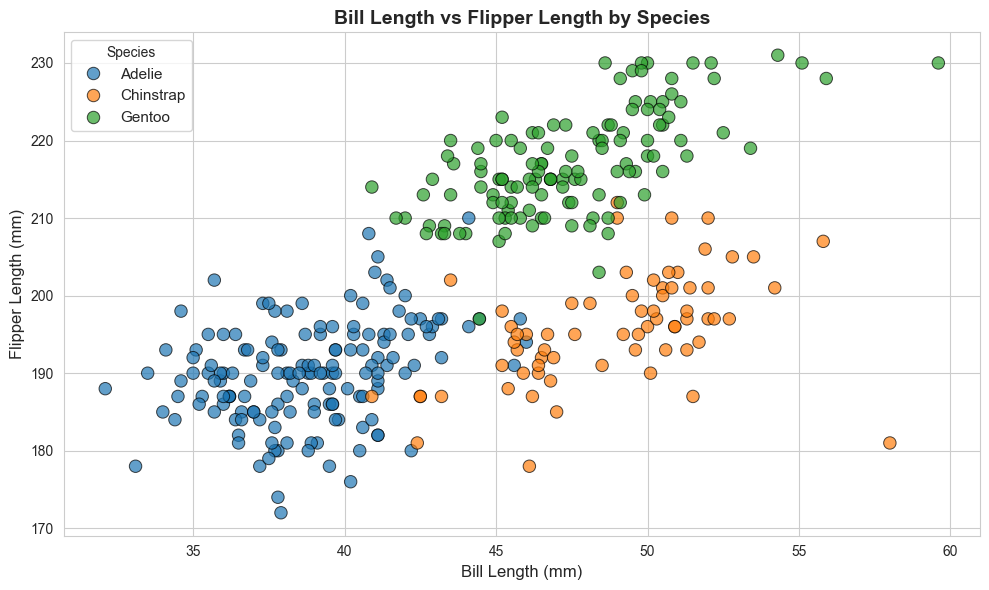

Correlation between bill_length_mm and flipper_length_mm: 0.656
Strong positive relationship


In [11]:
plt.figure(figsize=(10, 6))
scatter = sns.scatterplot(data=df_clean, x='bill_length_mm', y='flipper_length_mm', 
                          hue='species', palette=['#1f77b4', '#ff7f0e', '#2ca02c'], 
                          s=80, alpha=0.7, edgecolor='black')
plt.title('Bill Length vs Flipper Length by Species', fontsize=14, fontweight='bold')
plt.xlabel('Bill Length (mm)', fontsize=12)
plt.ylabel('Flipper Length (mm)', fontsize=12)
plt.legend(title='Species', fontsize=11)
plt.tight_layout()
plt.show()

# Correlation
corr = df_clean['bill_length_mm'].corr(df_clean['flipper_length_mm'])
print(f"Correlation between bill_length_mm and flipper_length_mm: {corr:.3f}")
if corr > 0.5:
    print("Strong positive relationship")
elif corr > 0:
    print("Moderate positive relationship")
elif corr < -0.5:
    print("Strong negative relationship")
elif corr < 0:
    print("Moderate negative relationship")
else:
    print("No clear relationship")

## Task 8: Line/Area Chart - Trend Across Ordered Variable
**Average body mass across bill length bins (ordered)**

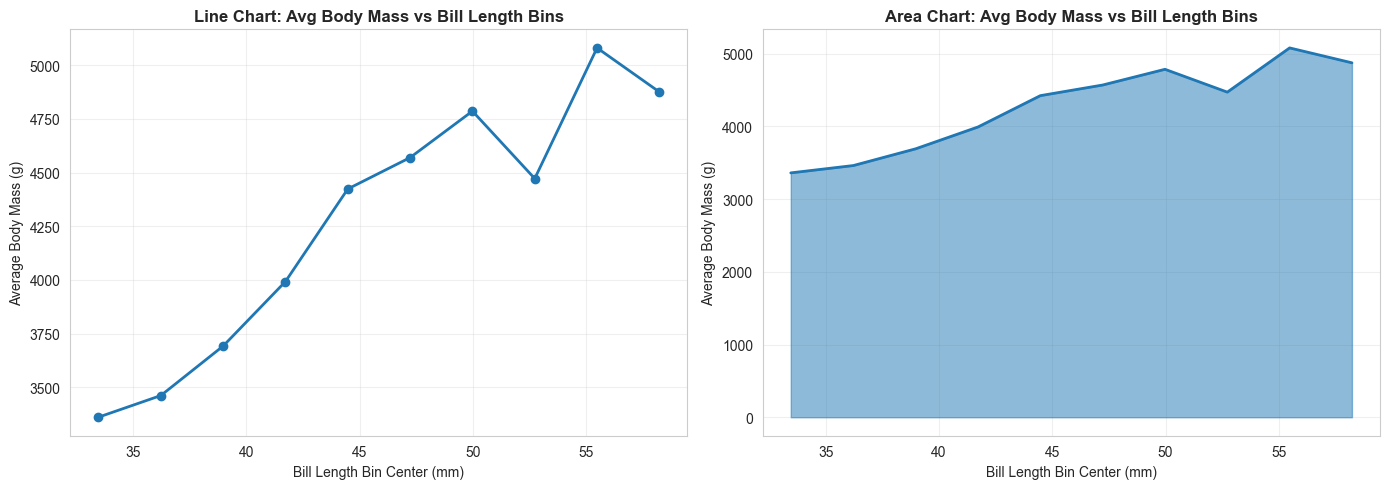

Comparison: The area chart fills the region under the line, emphasizing the magnitude 
of the values and creating a sense of 'volume.' The line chart focuses purely on 
the trend direction. The area fill can visually exaggerate differences, making 
the trend appear more dramatic than the line chart alone.


In [12]:
# Create ordered bins for bill_length_mm
df_clean['bill_length_bin'] = pd.cut(df_clean['bill_length_mm'], bins=10)
bin_avg = df_clean.groupby('bill_length_bin', observed=True)['body_mass_g'].mean().reset_index()
bin_avg['bin_center'] = bin_avg['bill_length_bin'].apply(lambda x: x.mid)
bin_avg = bin_avg.sort_values('bin_center')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Line chart
ax1.plot(bin_avg['bin_center'], bin_avg['body_mass_g'], marker='o', linewidth=2, markersize=6, color='#1f77b4')
ax1.set_title('Line Chart: Avg Body Mass vs Bill Length Bins', fontsize=12, fontweight='bold')
ax1.set_xlabel('Bill Length Bin Center (mm)', fontsize=10)
ax1.set_ylabel('Average Body Mass (g)', fontsize=10)
ax1.grid(True, alpha=0.3)

# Area chart
ax2.fill_between(bin_avg['bin_center'], bin_avg['body_mass_g'], alpha=0.5, color='#1f77b4')
ax2.plot(bin_avg['bin_center'], bin_avg['body_mass_g'], linewidth=2, color='#1f77b4')
ax2.set_title('Area Chart: Avg Body Mass vs Bill Length Bins', fontsize=12, fontweight='bold')
ax2.set_xlabel('Bill Length Bin Center (mm)', fontsize=10)
ax2.set_ylabel('Average Body Mass (g)', fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Comparison: The area chart fills the region under the line, emphasizing the magnitude ")
print("of the values and creating a sense of 'volume.' The line chart focuses purely on ")
print("the trend direction. The area fill can visually exaggerate differences, making ")
print("the trend appear more dramatic than the line chart alone.")

## Task 9: Graphical Integrity Check
**Bar chart from Task 2 with truncated y-axis vs normal y-axis**

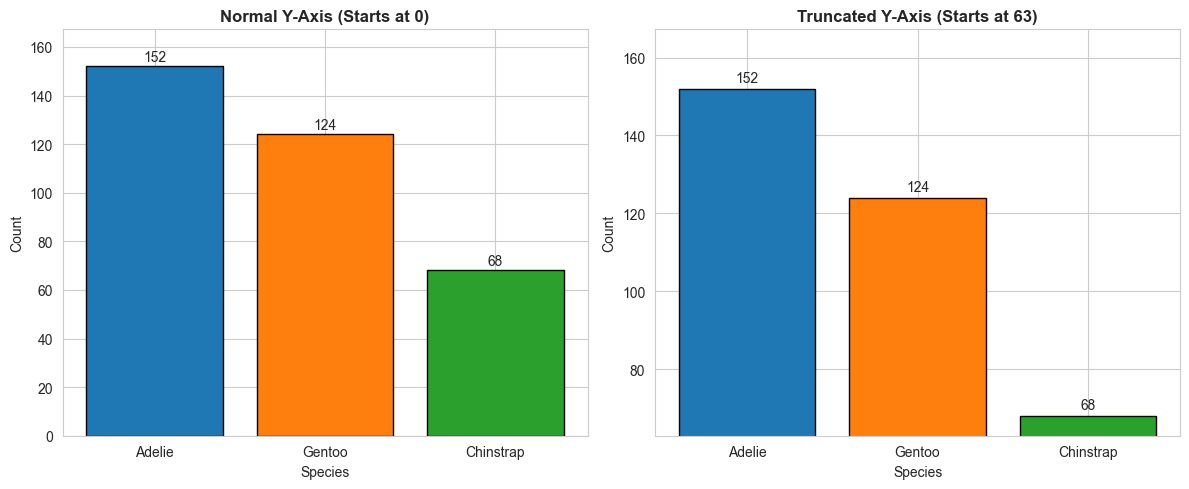

Graphical Integrity Analysis:
The truncated y-axis (right chart) exaggerates the differences between species counts.
Adelie appears disproportionately larger compared to Chinstrap and Gentoo.
The normal y-axis (left chart) shows the true proportional differences - 
Adelie has about 1.5x more penguins than the other species, not dramatically more.
Truncating the axis misleads viewers by making small differences appear large.


In [13]:
species_counts = df_clean['species'].value_counts()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Normal bar chart (y-axis starts at 0)
bars1 = ax1.bar(species_counts.index, species_counts.values, 
                color=['#1f77b4', '#ff7f0e', '#2ca02c'], edgecolor='black')
ax1.set_title('Normal Y-Axis (Starts at 0)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Species', fontsize=10)
ax1.set_ylabel('Count', fontsize=10)
ax1.set_ylim(0, max(species_counts.values) * 1.1)
for bar in bars1:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + 1,
             f'{int(height)}', ha='center', va='bottom', fontsize=10)

# Truncated bar chart (y-axis starts above 0)
min_val = min(species_counts.values)
truncated_start = min_val - 5
bars2 = ax2.bar(species_counts.index, species_counts.values, 
                color=['#1f77b4', '#ff7f0e', '#2ca02c'], edgecolor='black')
ax2.set_title(f'Truncated Y-Axis (Starts at {truncated_start})', fontsize=12, fontweight='bold')
ax2.set_xlabel('Species', fontsize=10)
ax2.set_ylabel('Count', fontsize=10)
ax2.set_ylim(truncated_start, max(species_counts.values) * 1.1)
for bar in bars2:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height + 1,
             f'{int(height)}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

print("Graphical Integrity Analysis:")
print("The truncated y-axis (right chart) exaggerates the differences between species counts.")
print("Adelie appears disproportionately larger compared to Chinstrap and Gentoo.")
print("The normal y-axis (left chart) shows the true proportional differences - ")
print("Adelie has about 1.5x more penguins than the other species, not dramatically more.")
print("Truncating the axis misleads viewers by making small differences appear large.")